# Análise do dataset Âmbito Jurídico para o GraphRAG/KAG (Neo4j)

Notebook de exploração que responde às perguntas que sustentam o modelo de grafo (`plano_grafo_neo4j.md`):

1. Qual o escopo real do corpus (categorias)?
2. Há duplicatas? Qual o tamanho final após dedup?
3. Qual o tamanho dos textos (chunking e custo de LLM)?
4. Quais normas, instituições, conceitos e autores aparecem de fato, e com que frequência?
5. Existem super-nós (termos em quase todo artigo)?
6. Quais conceitos co-ocorrem (candidatos a relações Concept-Concept)?
7. Qual subconjunto usar e qual amostra para o piloto de extração com LLM?

Ao final, a célula **Resumo** imprime os números que decidem o modelo.

## 1. Carga do dataset

In [19]:
%pip install -q pandas huggingface_hub pyarrow matplotlib

import re, unicodedata
from collections import Counter
from itertools import combinations

import pandas as pd
import matplotlib.pyplot as plt
from huggingface_hub import hf_hub_download

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

parquet_path = hf_hub_download(
    repo_id="celsowm/ambito_juridico_artigos",
    repo_type="dataset",
    filename="data/train-00000-of-00001.parquet",
)
df = pd.read_parquet(parquet_path)
print(f"Shape: {df.shape}")
print(f"Colunas: {list(df.columns)}")
df.head()

Note: you may need to restart the kernel to use updated packages.
Shape: (11373, 5)
Colunas: ['titulo', 'resumo', 'categoria', 'texto', 'link']


,titulo,resumo,categoria,texto,link
0,Manipulação de material genético e as suas consequências práticas e jurídicas,O presente artigo científico versa sobre as ciências biomédicas em confronto...,Biodireito,INTRODUÇÃO Práticas de natureza eugênica já eram utilizadas desde a Grécia a...,https://ambitojuridico.com.br/cadernos/biodireito/manipulacao-de-material-ge...
1,"Diretivas antecipadas de vontade, efetividade real?",Este artigo tem por objetivo trazer à discussão os efeitos jurídicos da even...,Biodireito,INTRODUÇÃO O término da Segunda Guerra Mundial é um marco importantíssimo pa...,https://ambitojuridico.com.br/cadernos/biodireito/diretivas-antecipadas-de-v...
2,"Mistanásia: A Morte Precoce, Miserável e Evitável Como Consequência da Viola...","A Mistanásia, é o oposto da Eutanásia, sendo caracterizada pela bioética e b...",Biodireito,"INTRODUÇÃO A Mistanásia é uma condição social desumana que atinge, em grande...",https://ambitojuridico.com.br/cadernos/biodireito/mistanasia-a-morte-precoce...
3,Consentimento livre e esclarecido: obrigação ética e jurídica do médico,O médico tem o dever de prestar ao paciente todas as informações relativas a...,Biodireito,"INTRODUÇÃO A Medicina é profissão regulamentada pela lei 3.268/1957, que ins...",https://ambitojuridico.com.br/cadernos/biodireito/consentimento-livre-e-escl...
4,Obrigação de Meios e Descabimento da Inversão do Ônus da Prova em Cirurgia P...,Artigo de revisão da doutrina e da jurisprudência afetas ao tema da modalida...,Biodireito,INTRODUÇÃO A jurisprudência majoritária e parte da doutrina entendem que a c...,https://ambitojuridico.com.br/cadernos/biodireito/obrigacao-de-meios-e-desca...


## 2. Tipos, nulos e vazios

In [20]:
print(df.dtypes, "\n")
print("Nulos:\n", df.isnull().sum(), "\n")
print("Strings vazias ou só espaços:")
for c in df.columns:
    print(f"  {c}: {(df[c].astype(str).str.strip() == '').sum()}")

titulo       str
resumo       str
categoria    str
texto        str
link         str
dtype: object 

Nulos:
 titulo       0
resumo       0
categoria    0
texto        0
link         0
dtype: int64 

Strings vazias ou só espaços:
  titulo: 0
  resumo: 1
  categoria: 0
  texto: 0
  link: 0


## 3. Escopo: categorias

Define se o corpus é só biodireito ou cobre várias áreas do Direito. Isso decide se o grafo é de domínio único ou amplo.

17 categorias


,artigos,%
categoria,,
Direito Constitucional,1547,13.60
Direito Penal,1196,10.52
Direito Administrativo,1046,9.20
Direito Processual Civil,1006,8.85
Direito Civil,899,7.90
Direito do Trabalho,899,7.90
Direito Ambiental,754,6.63
Direito Previdenciário,737,6.48
Direito de Família,637,5.60


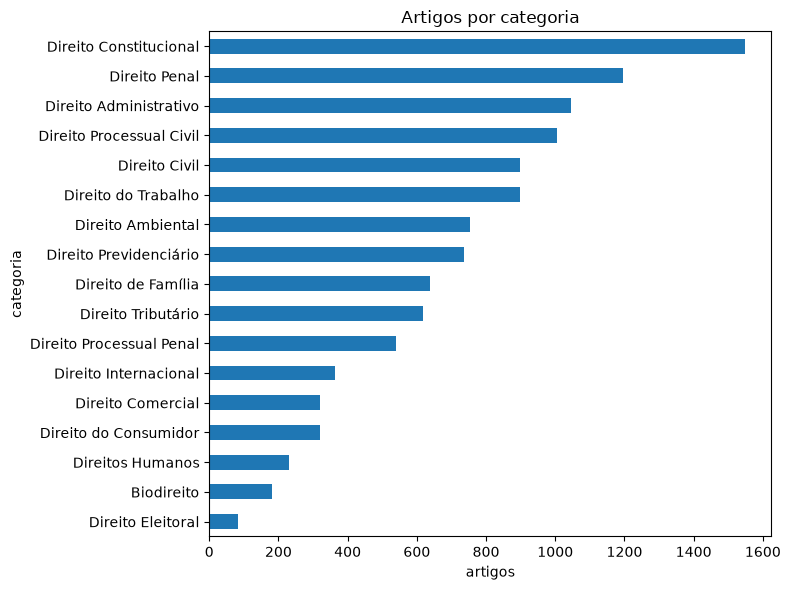

In [21]:
cat_counts = df["categoria"].value_counts()
cat_df = pd.DataFrame({"artigos": cat_counts, "%": (cat_counts / len(df) * 100).round(2)})
print(f"{df['categoria'].nunique()} categorias")
display(cat_df)

ax = cat_counts.sort_values().plot.barh(figsize=(8, 6), title="Artigos por categoria")
ax.set_xlabel("artigos")
plt.tight_layout(); plt.show()

## 4. Duplicatas

Compara duplicatas por título, link, texto e linha completa, e mostra exemplos para decidir o critério de dedup.

In [22]:
for col in ["titulo", "link", "texto", "resumo"]:
    print(f"{col}: {df[col].nunique()} únicos, {df.duplicated(col).sum()} repetidos")
print(f"Linhas completamente duplicadas: {df.duplicated().sum()}")

# mesmo link com categorias diferentes? (um artigo em várias categorias)
multi_cat = df.groupby("link")["categoria"].nunique()
print(f"\nLinks que aparecem em mais de uma categoria: {(multi_cat > 1).sum()}")

dup_titles = df[df.duplicated("titulo", keep=False)].sort_values("titulo")
print(f"\nExemplos de títulos repetidos ({len(dup_titles)} linhas):")
display(dup_titles[["titulo", "categoria", "link"]].head(12))

titulo: 10607 únicos, 766 repetidos
link: 10725 únicos, 648 repetidos
texto: 10605 únicos, 768 repetidos
resumo: 10407 únicos, 966 repetidos
Linhas completamente duplicadas: 628

Links que aparecem em mais de uma categoria: 17

Exemplos de títulos repetidos (1482 linhas):


,titulo,categoria,link
419,A (in)constitucionalidade da Lei 13.286/2016 que estabelece a responsabilida...,Direito Administrativo,https://ambitojuridico.com.br/cadernos/direito-administrativo/a-in-constituc...
422,A (in)constitucionalidade da Lei 13.286/2016 que estabelece a responsabilida...,Direito Administrativo,https://ambitojuridico.com.br/cadernos/direito-administrativo/a-in-constituc...
3593,A (in)convencionalidade do Estatuto do Desarmamento à luz da Convenção Ameri...,Direito Constitucional,https://ambitojuridico.com.br/cadernos/direito-constitucional/a-in-convencio...
3604,A (in)convencionalidade do Estatuto do Desarmamento à luz da Convenção Ameri...,Direito Constitucional,https://ambitojuridico.com.br/cadernos/direito-constitucional/a-in-convencio...
7438,A (in)suscetibilidade do delito antecedente no money laundering á luz da ace...,Direito Penal,https://ambitojuridico.com.br/cadernos/direito-penal/a-in-suscetibilidade-do...
7441,A (in)suscetibilidade do delito antecedente no money laundering á luz da ace...,Direito Penal,https://ambitojuridico.com.br/cadernos/direito-penal/a-in-suscetibilidade-do...
290,A Anulação do Ato Administrativo Por Vício no Motivo: Consequências na Reali...,Direito Administrativo,https://ambitojuridico.com.br/cadernos/direito-administrativo/a-anulacao-do-...
291,A Anulação do Ato Administrativo Por Vício no Motivo: Consequências na Reali...,Direito Administrativo,https://ambitojuridico.com.br/cadernos/direito-administrativo/a-anulacao-do-...
295,A Anulação do Ato Administrativo Por Vício no Motivo: Consequências na Reali...,Direito Administrativo,https://ambitojuridico.com.br/cadernos/direito-administrativo/a-anulacao-do-...
3388,A Composição Social da Lei Nº 10.216: Recortes Entre a Dignidade Humana e a ...,Direito Constitucional,https://ambitojuridico.com.br/cadernos/direitos-humanos/a-composicao-social-...


In [23]:
# Dedup: mantém a 1a ocorrência por link; depois por texto idêntico.
# O 'id' do Article será um hash do link.
import hashlib

work = df.drop_duplicates("link").drop_duplicates("texto").reset_index(drop=True)
work["id"] = work["link"].map(lambda s: hashlib.sha1(s.encode()).hexdigest()[:12])
print(f"Antes: {len(df)} | Depois: {len(work)} | Removidos: {len(df) - len(work)}")
assert work["id"].is_unique

Antes: 11373 | Depois: 10605 | Removidos: 768


## 5. Tamanho dos textos (chunking e custo de LLM)

       n_palavras   n_chars  n_palavras_resumo
count     10605.0   10605.0            10605.0
mean       4895.0   31917.0              135.0
std        3405.0   22173.0              416.0
min           1.0      10.0                0.0
5%         1204.0    7818.0               28.0
25%        2742.0   17867.0               66.0
50%        4203.0   27404.0              110.0
75%        6024.0   39321.0              155.0
95%       11176.0   72913.0              225.0
99%       17870.0  116897.0              313.0
max       56260.0  359203.0            21739.0

Por categoria (mediana de palavras):


,count,median,max
categoria,,,
Direito Constitucional,1411,4491.0,25698
Direito Penal,1104,4541.0,26393
Direito Administrativo,976,3972.5,27747
Direito Processual Civil,946,4148.0,28771
Direito Civil,850,4280.0,27960
Direito do Trabalho,819,4417.0,56260
Direito Ambiental,702,4002.5,25111
Direito Previdenciário,675,3186.0,15198
Direito de Família,589,4814.0,24451



Textos com menos de 300 palavras: 93 (candidatos a descarte)


,titulo,n_palavras
142,A proteção jurídica dos conhecimentos tradicionais associados no ordenamento...,195
518,Orientações para contratação de serviços de hotéis pelos órgãos do poder púb...,55
663,O tratamento favorecido das microempresas e das empresas de pequeno porte na...,208
967,As repercussões da Emenda Constitucional nº 19/98 sobre os institutos da est...,187
1024,Pregão: Uma análise do processo de aquisição de bens e serviços comuns pela ...,6
1100,Participação popular: controle judicial da alocação de recursos orçamentário...,87
1111,A superveniência da invalidade nos atos administrativos e a segurança jurídi...,66
1129,Municipalização do trânsito e da segurança pública,174


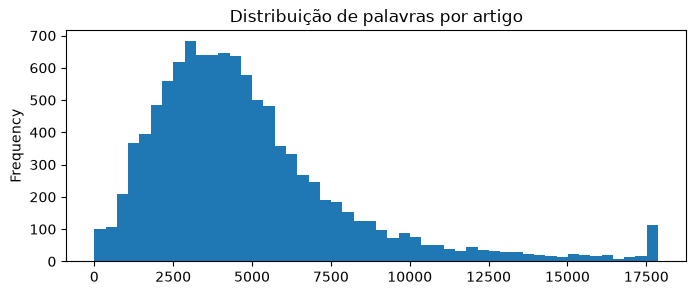

In [24]:
work["n_palavras"] = work["texto"].str.split().str.len()
work["n_chars"] = work["texto"].str.len()
work["n_palavras_resumo"] = work["resumo"].str.split().str.len()

print(work[["n_palavras", "n_chars", "n_palavras_resumo"]].describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(0))

print("\nPor categoria (mediana de palavras):")
display(work.groupby("categoria")["n_palavras"].agg(["count", "median", "max"]).sort_values("count", ascending=False))

short = work[work["n_palavras"] < 300]
print(f"\nTextos com menos de 300 palavras: {len(short)} (candidatos a descarte)")
display(short[["titulo", "n_palavras"]].head(8))

work["n_palavras"].clip(upper=work["n_palavras"].quantile(.99)).plot.hist(bins=50, figsize=(8, 3), title="Distribuição de palavras por artigo")
plt.show()

In [25]:
# Estimativas para planejar o pipeline (aprox.: 1 token ~ 4 caracteres em português)
CHUNK_TOKENS = 500
total_tokens = work["n_chars"].sum() / 4
print(f"Tokens estimados no corpus inteiro: {total_tokens/1e6:.1f} M")
print(f"Chunks de ~{CHUNK_TOKENS} tokens: {int(total_tokens / CHUNK_TOKENS):,}")
print(f"Tokens médios por artigo: {work['n_chars'].mean()/4:,.0f}")

print("\nCusto de extração por LLM (só entrada) varia com o subconjunto:")
for n in [200, 500, 1000, 2000, len(work)]:
    n = min(n, len(work))
    t = work["n_chars"].sample(n, random_state=0).sum() / 4 if n < len(work) else total_tokens
    print(f"  {n:>6} artigos -> {t/1e6:6.2f} M tokens de entrada")

Tokens estimados no corpus inteiro: 84.6 M
Chunks de ~500 tokens: 169,237
Tokens médios por artigo: 7,979

Custo de extração por LLM (só entrada) varia com o subconjunto:
     200 artigos ->   1.61 M tokens de entrada
     500 artigos ->   4.06 M tokens de entrada
    1000 artigos ->   7.97 M tokens de entrada
    2000 artigos ->  15.98 M tokens de entrada
   10605 artigos ->  84.62 M tokens de entrada


## 6. Estrutura interna dos artigos

Verifica se os textos têm seções reconhecíveis (INTRODUÇÃO, CONCLUSÃO...), úteis para chunking e para a propriedade `secao` do `Chunk`.

In [26]:
SECOES = ["INTRODUÇÃO", "CONCLUSÃO", "CONSIDERAÇÕES FINAIS", "REFERÊNCIAS", "DESENVOLVIMENTO", "METODOLOGIA", "RESULTADOS"]
rows = {s: work["texto"].str.contains(s, regex=False).mean() * 100 for s in SECOES}
print("% de artigos contendo o cabeçalho (maiúsculas):")
print(pd.Series(rows).round(1).to_string())

# Referências bibliográficas no fim do texto? (útil para extrair CitedAuthor)
print(f"\nArtigos com 'REFERÊNCIAS': {work['texto'].str.contains('REFERÊNCIAS').mean()*100:.1f}%")
work["texto"].iloc[0][:600]

% de artigos contendo o cabeçalho (maiúsculas):
INTRODUÇÃO              42.6
CONCLUSÃO               26.6
CONSIDERAÇÕES FINAIS    14.0
REFERÊNCIAS              0.3
DESENVOLVIMENTO          2.7
METODOLOGIA              0.7
RESULTADOS               0.5

Artigos com 'REFERÊNCIAS': 0.3%


'INTRODUÇÃO Práticas de natureza eugênica já eram utilizadas desde a Grécia antiga nos moldes da polis espartana, remontando a busca pelo aprimoramento físico dos soldados do exército desde os primórdios. Onde, os anciões instrumentavam através da seleção de crianças consideradas perfeitas, o melhoramento do patrimônio genético de seus cidadãos. Descartando assim, os considerados portadores de qualquer tipo de deficiência, deformidade ou imperfeição seguindo um rigoroso critério utilitarista para combate (SNELL, 2012). Em meados do século XVIII, uma norma universal trazia embutido uma nova visã'

## 7. Funções de normalização e contagem

Para casar termos independente de caixa e acentuação. `doc_freq` conta em quantos artigos cada padrão aparece, com a distribuição por categoria.

In [27]:
def norm(s: str) -> str:
    s = unicodedata.normalize("NFKD", s.lower())
    return "".join(c for c in s if not unicodedata.combining(c))

work["_n"] = (work["titulo"] + " " + work["resumo"] + " " + work["texto"]).map(norm)

def doc_freq(patterns: dict, col="_n"):
    """patterns: {rótulo: regex (já sem acento, minúsculo)} -> DataFrame com nº e % de artigos."""
    out = {}
    for label, rx in patterns.items():
        m = work[col].str.contains(rx, regex=True)
        out[label] = m
    mat = pd.DataFrame(out)
    res = pd.DataFrame({"artigos": mat.sum(), "%": (mat.mean() * 100).round(1)}).sort_values("artigos", ascending=False)
    return res, mat

## 8. Normas (`Norm`)

Quais normas realmente são citadas, e quantas variantes de grafia existem (insumo para entity resolution).

In [28]:
NORMAS = {
    "Constituição Federal":        r"constituicao federal|\bcf/?88\b|\bcrfb\b|constituicao da republica",
    "Código Civil":                r"codigo civil",
    "Código Penal":                r"codigo penal",
    "Código de Processo Civil":    r"codigo de processo civil|\bcpc\b",
    "Código de Defesa do Consumidor": r"codigo de defesa do consumidor|\bcdc\b",
    "Código de Ética Médica":      r"codigo de etica medica",
    "Lei de Biossegurança (11.105)": r"lei de biosseguranca|11\.?105",
    "Lei 9.434 (Transplantes)":    r"9\.?434",
    "ECA":                         r"estatuto da crianca|\beca\b",
    "Lei Geral de Proteção de Dados": r"\blgpd\b|13\.?709|lei geral de protecao de dados",
    "Declaração Universal dos Direitos Humanos": r"declaracao universal dos direitos humanos",
    "Resolução (CFM/CNS/outras)":  r"resolucao",
    "Súmula":                      r"sumula",
}
norm_df, norm_mat = doc_freq(NORMAS)
display(norm_df)

# Citações genéricas de lei: 'Lei nº 8.078/90', 'Lei 11.105/2005'
rx_lei = re.compile(r"[Ll]ei\s*(?:[Nn]º|[Nn]\.º|[Nn]o|[Nn]\.)?\s*(\d{1,2}\.?\d{3})(?:\s*/\s*(\d{2,4}))?")
leis = Counter()
for t in work["texto"]:
    for num, ano in set(rx_lei.findall(t)):
        leis[f"Lei {num}" + (f"/{ano}" if ano else "")] += 1
print(f"\nLeis distintas citadas: {len(leis)}")
print("Top 25:"); display(pd.Series(dict(leis.most_common(25)), name="artigos").to_frame())

# Variantes de grafia da mesma lei (mostra a necessidade de entity resolution)
variantes = Counter(m.group(0) for t in work["texto"].head(3000) for m in rx_lei.finditer(t))
print("\nExemplos de variantes de escrita:", list(variantes)[:15])

,artigos,%
Constituição Federal,7905,74.5
Resolução (CFM/CNS/outras),3266,30.8
Código Civil,3100,29.2
Código de Processo Civil,2585,24.4
Súmula,2441,23.0
Código Penal,1789,16.9
Código de Defesa do Consumidor,950,9.0
ECA,674,6.4
Declaração Universal dos Direitos Humanos,562,5.3
Lei de Biossegurança (11.105),100,0.9



Leis distintas citadas: 5897
Top 25:


,artigos
Lei 8.213/91,492
Lei 9.099/95,316
Lei 8.666/93,265
Lei 8.078/90,250
Lei 6.938/81,237
Lei 8.213,196
Lei 9.605/98,193
Lei 8.069/90,180
Lei 7.347/85,163
Lei 10.406,159



Exemplos de variantes de escrita: ['lei nº 13.123/2015', 'Lei nº 13.123/2015', 'lei 3.268/1957', 'lei 12.842/2013', 'lei 8.078/1990', 'lei nº 12.842/ 2013', 'lei 6.938/81', 'Lei n. 6.938/81', 'Lei 9.985', 'Lei 14.675', 'Lei 6.938', 'Lei n. 6.930/81', 'Lei nº 6.638', 'Lei nº 9.605', 'lei nº 3.688']


## 9. Instituições (`Institution`)

In [29]:
INSTITUICOES = {
    "STF":   r"\bstf\b|supremo tribunal federal",
    "STJ":   r"\bstj\b|superior tribunal de justica",
    "CFM":   r"\bcfm\b|conselho federal de medicina",
    "SUS":   r"\bsus\b|sistema unico de saude",
    "ANVISA":r"\banvisa\b",
    "OMS":   r"\boms\b|organizacao mundial da saude",
    "ONU":   r"\bonu\b|organizacao das nacoes unidas",
    "UNESCO":r"\bunesco\b",
    "CONEP/CEP": r"\bconep\b|comite de etica em pesquisa",
    "CTNBio":r"\bctnbio\b",
    "Ministério da Saúde": r"ministerio da saude",
    "Ministério Público": r"ministerio publico",
    "CNJ":   r"\bcnj\b|conselho nacional de justica",
}
inst_df, inst_mat = doc_freq(INSTITUICOES)
display(inst_df)

,artigos,%
STF,4130,38.9
STJ,3256,30.7
Ministério Público,2685,25.3
ONU,1154,10.9
CNJ,661,6.2
SUS,640,6.0
OMS,346,3.3
Ministério da Saúde,324,3.1
CFM,229,2.2
UNESCO,155,1.5


## 10. Conceitos e temas (`Concept`)

Para cada conceito, a cobertura global e a **precisão aproximada** da regra (quantos artigos citam o termo só 1 vez, sinal de menção marginal e não de tema).

In [30]:
CONCEITOS = {
    "Dignidade da pessoa humana": r"dignidade da pessoa humana|dignidade humana",
    "Autonomia (do paciente)":    r"autonomia (?:do|da) (?:paciente|vontade)|autonomia privada|autodeterminacao",
    "Consentimento informado":    r"consentimento (?:livre e esclarecido|informado)|\btcle\b",
    "Direito à saúde":            r"direito a saude",
    "Direito à vida":             r"direito a vida",
    "Eutanásia":                  r"eutanasia",
    "Ortotanásia":                r"ortotanasia",
    "Distanásia":                 r"distanasia",
    "Mistanásia":                 r"mistanasia",
    "Suicídio assistido":         r"suicidio assistido",
    "Clonagem":                   r"clonagem|clonar",
    "Células-tronco":             r"celulas.?tronco",
    "Manipulação genética":       r"manipulacao genetica|edicao genetica|crispr|engenharia genetica",
    "Patrimônio genético":        r"patrimonio genetico",
    "Aborto":                     r"\baborto|interrupcao da gravidez",
    "Transplante de órgãos":      r"transplante|doacao de orgaos",
    "Reprodução assistida":       r"reproducao (?:humana )?assistida|fertilizacao in vitro|inseminacao",
    "Diretivas antecipadas":      r"diretivas antecipadas|testamento vital",
    "Erro médico / resp. civil médica": r"erro medico|responsabilidade civil (?:do|medica)|obrigacao de meios",
    "Bioética":                   r"bioetica",
    "Biodireito":                 r"biodireito",
    "Direitos fundamentais":      r"direitos? fundamentais?",
    "Direitos da personalidade":  r"direitos? da personalidade",
    "Princípio da precaução":     r"principio da precaucao",
    "Prontuário / sigilo médico": r"prontuario|sigilo medico|segredo medico",
    "Pesquisa com seres humanos": r"pesquisa (?:com|em) seres humanos",
    "Saúde pública":              r"saude publica",
    "Judicialização da saúde":    r"judicializacao da saude|fornecimento de medicamentos",
}
conc_df, conc_mat = doc_freq(CONCEITOS)
display(conc_df)

# menções marginais: artigos em que o termo aparece só 1 vez
marg = {}
for label, rx in CONCEITOS.items():
    cnt = work["_n"].str.count(rx)
    com = cnt[cnt > 0]
    marg[label] = round((com == 1).mean() * 100, 1) if len(com) else None
print("\n% das menções que aparecem só 1 vez no artigo (alto = regra gera ruído):")
print(pd.Series(marg).sort_values(ascending=False).to_string())

,artigos,%
Dignidade da pessoa humana,3955,37.3
Direitos fundamentais,3930,37.1
Direito à vida,1624,15.3
Autonomia (do paciente),1383,13.0
Saúde pública,758,7.1
Direito à saúde,557,5.3
Direitos da personalidade,540,5.1
Erro médico / resp. civil médica,466,4.4
Aborto,331,3.1
Bioética,195,1.8



% das menções que aparecem só 1 vez no artigo (alto = regra gera ruído):
Pesquisa com seres humanos          78.6
Manipulação genética                72.0
Clonagem                            69.6
Transplante de órgãos               67.6
Prontuário / sigilo médico          66.1
Patrimônio genético                 65.8
Saúde pública                       62.3
Direito à vida                      60.0
Células-tronco                      55.4
Autonomia (do paciente)             55.0
Aborto                              53.8
Direito à saúde                     51.7
Direitos da personalidade           48.9
Suicídio assistido                  46.9
Biodireito                          45.5
Bioética                            45.1
Erro médico / resp. civil médica    44.8
Consentimento informado             41.7
Eutanásia                           41.2
Princípio da precaução              40.8
Reprodução assistida                36.8
Mistanásia                          36.4
Judicialização da saúde 

## 11. Super-nós

Termos presentes em mais de ~30% dos artigos viram nós com grau enorme e pouco poder discriminativo; entram com peso (ex.: mencionado ≥ N vezes) ou ficam fora das relações de tema.

In [31]:
todos = pd.concat([norm_df.assign(tipo="Norm"), inst_df.assign(tipo="Institution"), conc_df.assign(tipo="Concept")])
super_nos = todos[todos["%"] >= 30].sort_values("%", ascending=False)
print("Candidatos a super-nó (>=30% dos artigos):")
display(super_nos)
print("\nTermos raros (<0.5% dos artigos) — pouco úteis como nós:")
display(todos[todos["%"] < 0.5])

Candidatos a super-nó (>=30% dos artigos):


,artigos,%,tipo
Constituição Federal,7905,74.5,Norm
STF,4130,38.9,Institution
Dignidade da pessoa humana,3955,37.3,Concept
Direitos fundamentais,3930,37.1,Concept
Resolução (CFM/CNS/outras),3266,30.8,Norm
STJ,3256,30.7,Institution



Termos raros (<0.5% dos artigos) — pouco úteis como nós:


,artigos,%,tipo
Lei 9.434 (Transplantes),44,0.4,Norm
Lei Geral de Proteção de Dados,20,0.2,Norm
CONEP/CEP,24,0.2,Institution
CTNBio,15,0.1,Institution
Distanásia,46,0.4,Concept
Suicídio assistido,32,0.3,Concept
Diretivas antecipadas,26,0.2,Concept
Mistanásia,22,0.2,Concept
Pesquisa com seres humanos,14,0.1,Concept


## 12. Conceitos por categoria

In [32]:
mat = conc_mat.copy()
mat["categoria"] = work["categoria"].values
por_cat = mat.groupby("categoria").mean().mul(100).round(1)
# categorias com mais de 30 artigos para evitar ruído
grandes = work["categoria"].value_counts()[lambda s: s >= 30].index
display(por_cat.loc[grandes].T)

categoria,Direito Constitucional,Direito Penal,Direito Administrativo,Direito Processual Civil,Direito Civil,Direito do Trabalho,Direito Ambiental,Direito Previdenciário,Direito de Família,Direito Tributário,Direito Processual Penal,Direito Internacional,Direito Comercial,Direito do Consumidor,Direitos Humanos,Biodireito,Direito Eleitoral
Dignidade da pessoa humana,51.2,40.7,17.4,18.7,40.4,46.2,29.3,43.6,67.2,14.7,38.7,28.1,11.3,35.8,68.0,75.3,14.5
Autonomia (do paciente),15.3,12.2,7.0,7.7,26.8,14.0,4.7,3.3,19.7,3.8,5.3,20.7,13.2,24.5,27.4,43.3,3.6
Consentimento informado,0.7,0.4,0.0,0.1,1.5,0.4,0.0,0.0,1.5,0.0,0.0,0.0,0.0,2.3,0.9,19.7,0.0
Direito à saúde,14.4,2.4,3.6,1.2,1.9,4.3,4.7,9.2,2.5,1.7,1.0,3.4,1.0,5.3,14.2,24.7,0.0
Direito à vida,24.7,14.3,5.0,7.5,17.1,13.6,20.8,10.2,31.1,6.4,10.6,10.5,3.9,11.9,33.8,48.9,8.4
Eutanásia,1.9,1.9,0.0,0.0,1.3,0.1,0.9,0.0,0.2,0.0,0.0,0.6,0.0,0.3,3.2,20.8,0.0
Ortotanásia,0.9,0.5,0.0,0.0,0.9,0.1,0.0,0.0,0.0,0.0,0.0,0.6,0.0,0.0,0.9,11.8,0.0
Distanásia,0.7,0.5,0.0,0.0,0.6,0.0,0.0,0.0,0.0,0.0,0.0,0.6,0.0,0.0,1.4,11.8,0.0
Mistanásia,0.3,0.3,0.0,0.0,0.4,0.0,0.0,0.0,0.0,0.0,0.0,0.6,0.0,0.0,0.9,4.5,0.0
Suicídio assistido,0.9,0.3,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.6,0.0,0.0,0.9,6.7,0.0


## 13. Camada temática bio/saúde (opcional)

Escopo do projeto é o corpus inteiro; aqui só medimos quanto de cada categoria toca bio/saúde, para uma camada temática extra.

In [33]:
dominio_rx = r"bioetica|biodireito|eutanasia|ortotanasia|clonagem|celulas.?tronco|genetic|transplante|paciente|medic|saude|aborto|reproducao assistida|embriao"
work["_dominio"] = work["_n"].str.count(dominio_rx)
work["eh_dominio"] = work["_dominio"] >= 10   # >=10 ocorrências -> tema, não menção

esc = work.groupby("categoria")["eh_dominio"].agg(["sum", "count", "mean"]).rename(columns={"sum": "no_dominio", "count": "total", "mean": "fracao"})
esc["fracao"] = (esc["fracao"] * 100).round(1)
display(esc.sort_values("no_dominio", ascending=False))
print(f"\nArtigos no domínio bio/saúde: {work['eh_dominio'].sum()} de {len(work)}")

,no_dominio,total,fracao
categoria,,,
Direito Previdenciário,202,675,29.9
Direito Constitucional,201,1411,14.2
Biodireito,161,178,90.4
Direito Penal,136,1104,12.3
Direito do Trabalho,131,819,16.0
Direito Civil,95,850,11.2
Direito Ambiental,70,702,10.0
Direito de Família,69,589,11.7
Direito Administrativo,67,976,6.9



Artigos no domínio bio/saúde: 1306 de 10605


## 14. Co-ocorrência de conceitos

Pares que aparecem juntos com frequência são candidatos a relações `Concept-Concept`. Medidos por **lift** (> 1 = aparecem juntos mais do que o acaso) para não destacar só termos comuns.

In [34]:
N = len(work)
labels = list(conc_mat.columns)
freq = conc_mat.mean()
pares = []
for a, b in combinations(labels, 2):
    co = (conc_mat[a] & conc_mat[b]).sum()
    if co >= 20:
        lift = (co / N) / (freq[a] * freq[b])
        pares.append((a, b, co, round(lift, 2)))
pares_df = pd.DataFrame(pares, columns=["conceito_a", "conceito_b", "artigos_juntos", "lift"])
print("Top por lift (relações mais específicas):")
display(pares_df.sort_values("lift", ascending=False).head(25))
print("Top por frequência bruta:")
display(pares_df.sort_values("artigos_juntos", ascending=False).head(15))

Top por lift (relações mais específicas):


,conceito_a,conceito_b,artigos_juntos,lift
114,Distanásia,Diretivas antecipadas,22,195.08
113,Distanásia,Suicídio assistido,27,194.52
107,Ortotanásia,Distanásia,42,182.69
109,Ortotanásia,Diretivas antecipadas,23,177.01
108,Ortotanásia,Suicídio assistido,27,168.83
98,Eutanásia,Suicídio assistido,32,93.03
96,Eutanásia,Distanásia,45,91.00
95,Eutanásia,Ortotanásia,51,89.52
102,Eutanásia,Diretivas antecipadas,24,85.87
97,Eutanásia,Mistanásia,20,84.57


Top por frequência bruta:


,conceito_a,conceito_b,artigos_juntos,lift
20,Dignidade da pessoa humana,Direitos fundamentais,2493,1.70
3,Dignidade da pessoa humana,Direito à vida,1167,1.93
89,Direito à vida,Direitos fundamentais,1137,1.89
0,Dignidade da pessoa humana,Autonomia (do paciente),852,1.65
44,Autonomia (do paciente),Direitos fundamentais,784,1.53
2,Dignidade da pessoa humana,Direito à saúde,427,2.06
69,Direito à saúde,Direitos fundamentais,415,2.01
21,Dignidade da pessoa humana,Direitos da personalidade,412,2.05
24,Dignidade da pessoa humana,Saúde pública,405,1.43
180,Direitos fundamentais,Saúde pública,404,1.44


## 15. Autores citados (`CitedAuthor`)

Heurística: padrão `(SOBRENOME, 2010)` / `SOBRENOME (2010)` do estilo ABNT. Serve só para estimar se vale criar o nó.

In [35]:
rx_aut = re.compile(r"\(([A-ZÁÉÍÓÚÂÊÔÃÕÇ][A-ZÁÉÍÓÚÂÊÔÃÕÇ'\-]{2,}),?\s*(?:\d{4})")
rx_aut2 = re.compile(r"\b([A-ZÁÉÍÓÚÂÊÔÃÕÇ][a-záéíóúâêôãõç]{3,})\s*\((\d{4})\)")
autores = Counter()
for t in work["texto"]:
    nomes = {m.title() for m in rx_aut.findall(t)} | {m[0] for m in rx_aut2.findall(t)}
    autores.update(nomes)
print(f"Sobrenomes distintos detectados: {len(autores)}")
display(pd.Series(dict(autores.most_common(30)), name="artigos").to_frame())

nomes_ref = {"Kant": r"\bkant\b", "Mill": r"\bstuart mill\b", "Canotilho": r"canotilho", "Diniz": r"maria helena diniz",
             "Galton": r"galton", "He Jiankui": r"jiankui", "Namba": r"\bnamba\b", "Ricci": r"\bricci\b"}
print("\nAutores citados no plano:")
display(doc_freq(nomes_ref)[0])

Sobrenomes distintos detectados: 7693


,artigos
Brasil,1216
Silva,762
Oliveira,354
Gonçalves,351
Santos,330
Moraes,306
Dias,292
Diniz,284
Carvalho,269
Barroso,260



Autores citados no plano:


,artigos,%
Canotilho,628,5.9
Diniz,529,5.0
Kant,337,3.2
Mill,44,0.4
Galton,11,0.1
Ricci,8,0.1
Namba,5,0.0
He Jiankui,1,0.0


## 16. Subconjunto de trabalho e piloto (corpus inteiro)

Escopo decidido: **corpus inteiro**, processado por amostra estratificada por categoria (custo de LLM controlado).

- `piloto`: ~3 artigos por categoria, para validar prompt de NER/RE e schema.
- `subconjunto`: ~1.000 artigos estratificados (proporcional, mínimo 20 por categoria) para a ingestão completa no Neo4j.
- Filtro de qualidade: 800 a 12.000 palavras, com seção de conclusão ou referências.

In [36]:
qual = work[work["n_palavras"].between(800, 12000)]
print(f"Artigos com tamanho adequado: {len(qual)} de {len(work)}")

# piloto: 3 por categoria
piloto = qual.groupby("categoria").sample(n=3, random_state=42)

# subconjunto: proporcional ao tamanho da categoria, mínimo 20 por categoria
SUB_N = 1000
cota = (qual["categoria"].value_counts(normalize=True) * SUB_N).round().clip(lower=20).astype(int)
partes = [qual[qual["categoria"] == c].sample(min(n, (qual["categoria"] == c).sum()), random_state=7) for c, n in cota.items()]
subconjunto = pd.concat(partes)
subconjunto = subconjunto[~subconjunto["id"].isin(piloto["id"])]

print(f"Piloto: {len(piloto)} | Subconjunto: {len(subconjunto)}")
print(f"Tokens estimados do subconjunto: {subconjunto['n_chars'].sum()/4/1e6:.1f} M (entrada, sem contar saída)")
display(pd.DataFrame({"piloto": piloto["categoria"].value_counts(), "subconjunto": subconjunto["categoria"].value_counts()}))

Artigos com tamanho adequado: 9912 de 10605
Piloto: 51 | Subconjunto: 1011
Tokens estimados do subconjunto: 7.3 M (entrada, sem contar saída)


,piloto,subconjunto
categoria,,
Biodireito,3,20
Direito Administrativo,3,93
Direito Ambiental,3,67
Direito Civil,3,80
Direito Comercial,3,29
Direito Constitucional,3,133
Direito Eleitoral,3,17
Direito Internacional,3,31
Direito Penal,3,105


## 17. Salvar dados processados

In [37]:
out_cols = ["id", "titulo", "resumo", "categoria", "texto", "link", "n_palavras", "n_chars", "eh_dominio"]
work[out_cols].to_parquet("processed_ambito_juridico.parquet", index=False)
piloto[out_cols].to_parquet("piloto_ambito_juridico.parquet", index=False)
subconjunto[out_cols].to_parquet("subconjunto_ambito_juridico.parquet", index=False)
print("Salvos: processed, piloto e subconjunto (.parquet)")
print("Texto original preservado (sem lower-case) para o NER.")

Salvos: processed, piloto e subconjunto (.parquet)
Texto original preservado (sem lower-case) para o NER.


## 18. Resumo para decisão do modelo

In [38]:
print("=" * 60)
print(f"Artigos brutos: {len(df)} | únicos: {len(work)}")
print(f"Categorias: {work['categoria'].nunique()} | maior: {work['categoria'].value_counts().idxmax()} ({work['categoria'].value_counts().max()})")
print(f"Artigos no domínio bio/saúde: {work['eh_dominio'].sum()} ({work['eh_dominio'].mean()*100:.0f}%)")
print(f"Mediana de palavras/artigo: {work['n_palavras'].median():.0f} | tokens totais ~ {work['n_chars'].sum()/4/1e6:.1f} M")
print(f"Leis distintas citadas: {len(leis)} | sobrenomes de autores: {len(autores)}")
print(f"Conceitos com >=30% de cobertura (super-nós): {list(super_nos[super_nos.tipo=='Concept'].index)}")
print(f"Conceitos com <1% de cobertura: {list(conc_df[conc_df['%'] < 1].index)}")
print("=" * 60)

Artigos brutos: 11373 | únicos: 10605
Categorias: 17 | maior: Direito Constitucional (1411)
Artigos no domínio bio/saúde: 1306 (12%)
Mediana de palavras/artigo: 4203 | tokens totais ~ 84.6 M
Leis distintas citadas: 5897 | sobrenomes de autores: 7693
Conceitos com >=30% de cobertura (super-nós): ['Dignidade da pessoa humana', 'Direitos fundamentais']
Conceitos com <1% de cobertura: ['Células-tronco', 'Consentimento informado', 'Clonagem', 'Ortotanásia', 'Distanásia', 'Suicídio assistido', 'Diretivas antecipadas', 'Mistanásia', 'Pesquisa com seres humanos']
